In [2]:

import requests

url = "https://www.gutenberg.org/cache/epub/164/pg164.txt"
text = requests.get(url).content.decode("utf-8-sig")
text = text.split("*** START OF THE PROJECT GUTENBERG EBOOK", 1)[1]
text = text.split("\n", 1)[1].split("*** END OF THE PROJECT GUTENBERG EBOOK", 1)[0]

print("Toplam karakter:", len(text))
print(text[:300])


Toplam karakter: 610279




Twenty Thousand Leagues under the Sea

by Jules Verne




Contents

 PART I
 CHAPTER I A SHIFTING REEF
 CHAPTER II PRO AND CON
 CHAPTER III I FORM MY RESOLUTION
 CHAPTER IV NED LAND
 CHAPTER V AT A VENTURE
 CHAPTER VI AT FULL STEAM
 CHAPTER VII AN UNKNOWN SPECIES OF WHALE
 C


**1. Veri Toplama**

Bu aşamada Jules Verne'in Twenty Thousand Leagues under the Sea adlı eserinin İngilizce UTF-8 sürümü Project Gutenberg üzerinden alınmıştır. Gutenberg'e ait başlangıç ve bitiş açıklamaları metinden çıkarılarak analiz edilecek içerik hazırlanmıştır.

In [3]:

import re, nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download("stopwords", quiet=True)

tokens = re.findall(r"[a-z]+", text.lower())
tokens = [w for w in tokens if len(w) >= 3]

stops = set(stopwords.words("english"))
clean_tokens = [w for w in tokens if w not in stops]

stemmer = PorterStemmer()
stems = [stemmer.stem(w) for w in clean_tokens]

print("Ham token:", len(tokens))
print("Temiz token:", len(clean_tokens))
print("Benzersiz kök:", len(set(stems)))


Ham token: 82658
Temiz token: 51918
Benzersiz kök: 5821


**2. Metin Ön İşleme**

Metin küçük harflere dönüştürülmüş, düzenli ifadeler (Regex) kullanılarak özel karakterler ve sayılar temizlenmiştir. Kelimeler tokenlara ayrılmış, üç karakterden kısa tokenlar ve İngilizce etkisiz kelimeler (stopwords) çıkarılmıştır. Son olarak PorterStemmer algoritmasıyla kök indirgeme işlemi uygulanmıştır.

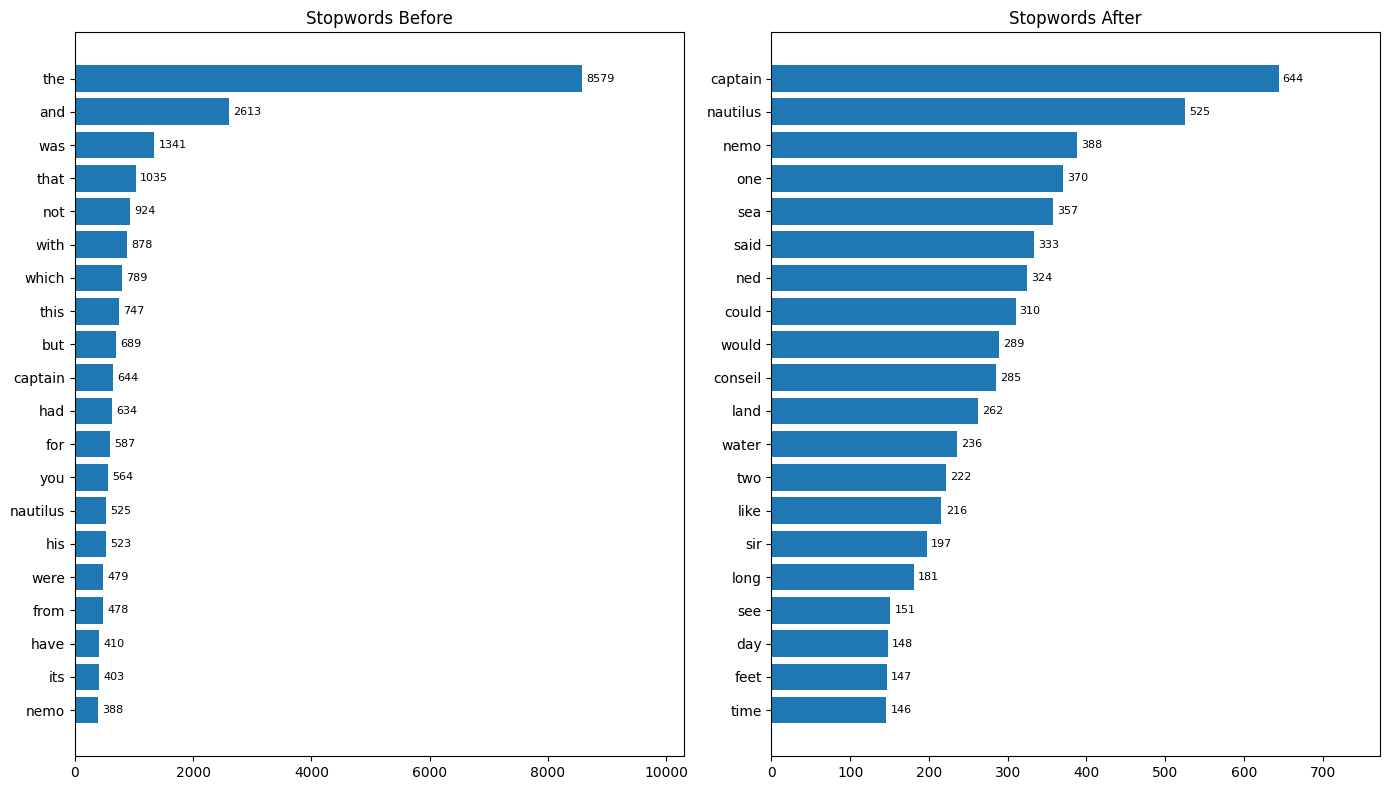

In [4]:

from collections import Counter
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

for ax, words, title in zip(axes, [tokens, clean_tokens],
                             ["Stopwords Before", "Stopwords After"]):
    top20 = Counter(words).most_common(20)
    labels, counts = zip(*top20[::-1])
    bars = ax.barh(labels, counts)
    ax.bar_label(bars, padding=3, fontsize=8)
    ax.set_xlim(0, max(counts) * 1.2)
    ax.set_title(title)

plt.tight_layout()
plt.show()


**3. Kelime Frekans Analizi**

Metindeki en sık kullanılan 20 kelime, etkisiz kelimeler (stopwords) çıkarılmadan önce ve çıkarıldıktan sonra hesaplanmıştır. Sonuçlar yatay çubuk grafiklerle karşılaştırılarak etkisiz kelimelerin metindeki baskınlığı ve temizlik sonrası öne çıkan kavramlar incelenmiştir.

15 Bigram: [(('captain', 'nemo'), 387), (('ned', 'land'), 196), (('said', 'conseil'), 53), (('abraham', 'lincoln'), 46), (('sir', 'said'), 32), (('next', 'day'), 30), (('said', 'ned'), 30), (('red', 'sea'), 26), (('said', 'captain'), 22), (('friend', 'ned'), 21), (('yes', 'sir'), 19), (('drawing', 'room'), 19), (('miles', 'hour'), 18), (('could', 'see'), 18), (('electric', 'light'), 18)]
10 Trigram: [(('said', 'captain', 'nemo'), 22), (('said', 'ned', 'land'), 18), (('replied', 'captain', 'nemo'), 13), (('replied', 'ned', 'land'), 11), (('captain', 'nemo', 'took'), 8), (('captain', 'nemo', 'went'), 8), (('forty', 'eight', 'hours'), 7), (('twenty', 'four', 'hours'), 7), (('captain', 'nemo', 'said'), 7), (('captain', 'nemo', 'stopped'), 7)]


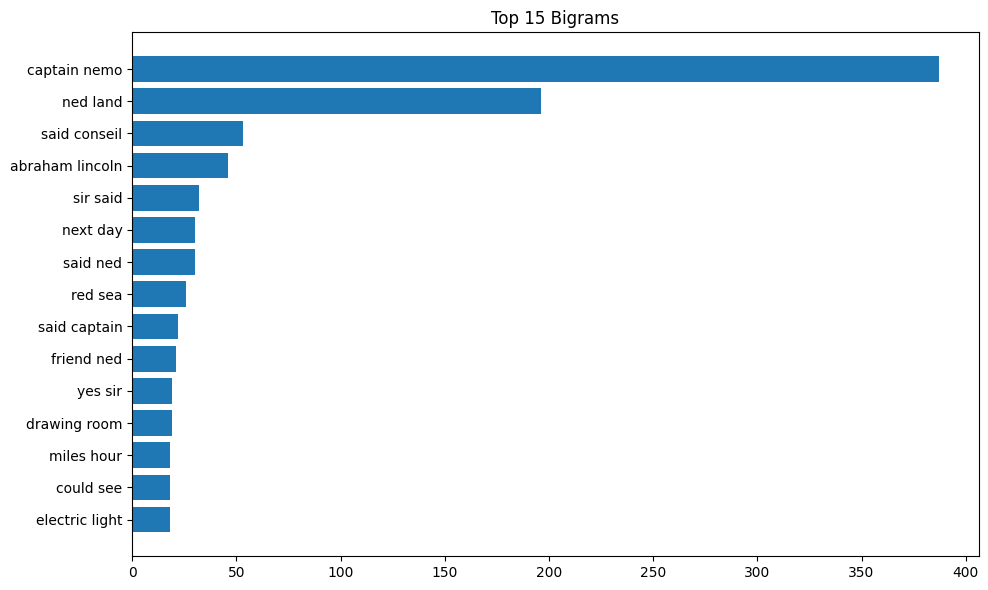

In [5]:

from collections import Counter

bigrams = Counter((a,b) for a,b in zip(tokens,tokens[1:])
                  if a not in stops and b not in stops).most_common(15)

trigrams = Counter((a,b,c) for a,b,c in zip(tokens,tokens[1:],tokens[2:])
                   if all(w not in stops for w in (a,b,c))).most_common(10)

print("15 Bigram:", bigrams)
print("10 Trigram:", trigrams)

words, counts = zip(*[(" ".join(w), n) for w,n in bigrams[::-1]])
plt.figure(figsize=(10,6))
plt.barh(words, counts)
plt.title("Top 15 Bigrams")
plt.tight_layout()
plt.show()


**4. N-gram Analizi**

Metinde ardışık olarak kullanılan kelime çiftleri (bigram) ve üçlüleri (trigram) analiz edilmiştir. Stopwords içermeyen en sık 15 bigram ve 10 trigram belirlenmiş, bigram frekansları çubuk grafikle görselleştirilmiştir. Böylece eserde sık tekrarlanan kelime birlikteliklerinin ortaya çıkarılması amaçlanmıştır.

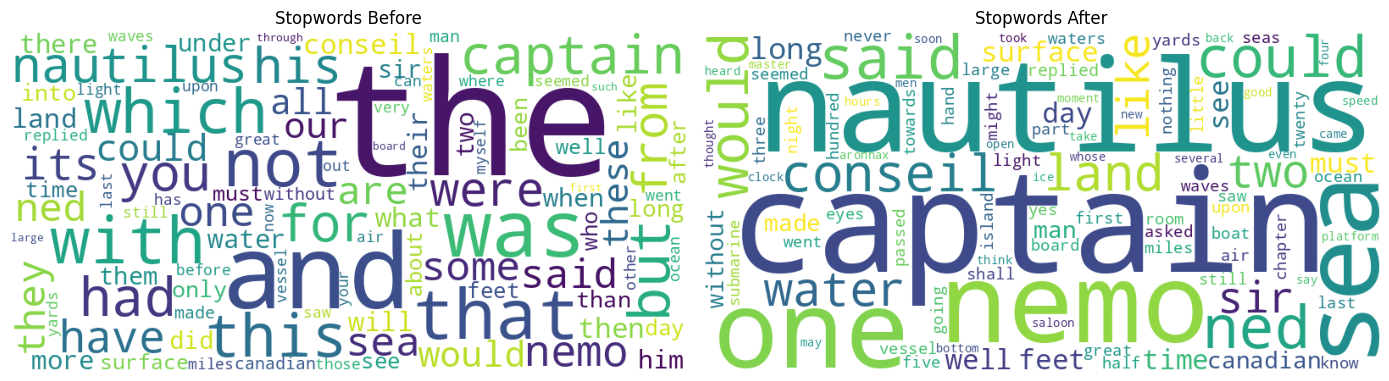

In [6]:

from wordcloud import WordCloud

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, words, title in zip(axes, [tokens, clean_tokens],
                            ["Stopwords Before", "Stopwords After"]):
    cloud = WordCloud(width=800, height=400,
                      background_color="white").generate_from_frequencies(
                          dict(Counter(words).most_common(100)))
    ax.imshow(cloud)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


**5. Kelime Bulutu Analizi**

Metinde en sık kullanılan 100 kelime, etkisiz kelimeler çıkarılmadan önce ve çıkarıldıktan sonra kelime bulutlarıyla görselleştirilmiştir. Kelimelerin büyüklüğü kullanım sıklıklarını temsil etmektedir. Bu karşılaştırma, metnin öne çıkan kavramlarını belirlemek amacıyla yapılmıştır.

Toplam karakter: 610279
Toplam token: 82658
Temiz token: 51918
Benzersiz kelime: 8506
Benzersiz kök: 5821
Stopwords azalması: %37.19
Ortalama kelime uzunluğu: 6.10


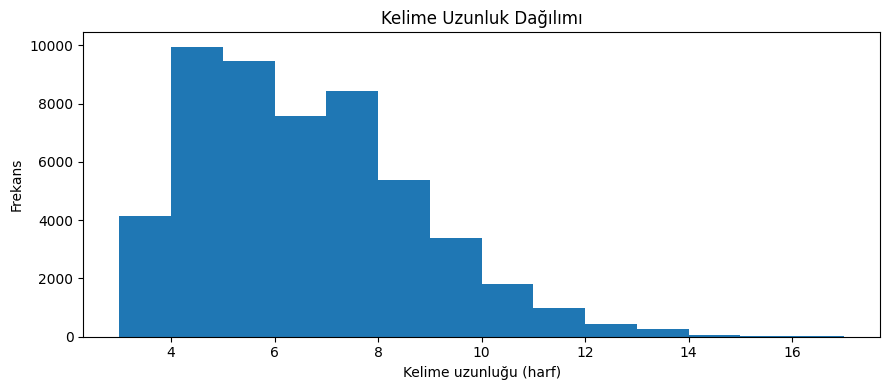

In [7]:

azalma = 100 * (1 - len(clean_tokens) / len(tokens))
uzunluklar = [len(w) for w in clean_tokens]

print("Toplam karakter:", len(text))
print("Toplam token:", len(tokens))
print("Temiz token:", len(clean_tokens))
print("Benzersiz kelime:", len(set(clean_tokens)))
print("Benzersiz kök:", len(set(stems)))
print(f"Stopwords azalması: %{azalma:.2f}")
print(f"Ortalama kelime uzunluğu: {sum(uzunluklar)/len(uzunluklar):.2f}")

plt.figure(figsize=(9,4))
plt.hist(uzunluklar, bins=range(3, max(uzunluklar)+2))
plt.xlabel("Kelime uzunluğu (harf)")
plt.ylabel("Frekans")
plt.title("Kelime Uzunluk Dağılımı")
plt.tight_layout()
plt.show()


**6. İstatistiksel Analiz**

Eserin toplam karakter ve kelime sayıları, benzersiz kelime ve kök sayıları hesaplanmıştır. Stopwords temizliğinin token sayısına etkisi yüzdesel olarak belirlenmiştir. Ayrıca ortalama kelime uzunluğu hesaplanmış ve kelime uzunluklarının dağılımı histogramla görselleştirilmiştir.

**7. Bulguların Değerlendirilmesi**

Jules Verne'in *Twenty Thousand Leagues under the Sea* adlı eserinde 82.658 token tespit edilmiş, etkisiz kelimelerin çıkarılmasıyla bu sayı 51.918'e düşerek %37,19 azalmıştır. Metinde 8.506 benzersiz kelime ve 5.821 benzersiz kök belirlenmiş, ortalama kelime uzunluğu 6,10 harf olarak hesaplanmıştır. Frekans analizi ve kelime bulutlarında *captain, nautilus, nemo* kelimelerinin öne çıkması, eserin karakterleri ve denizaltı yolculuğu etrafında şekillendiğini göstermektedir. Bigram ve trigram analizlerinde *Captain Nemo* ve *Ned Land* gibi karakter adlarının sıklıkla tekrarlanması, anlatının karakter odaklı yapısını desteklemektedir. Ayrıca *electric light* ifadesinin öne çıkması, eserin bilim ve teknolojiyle ilişkili içeriğine işaret etmektedir.

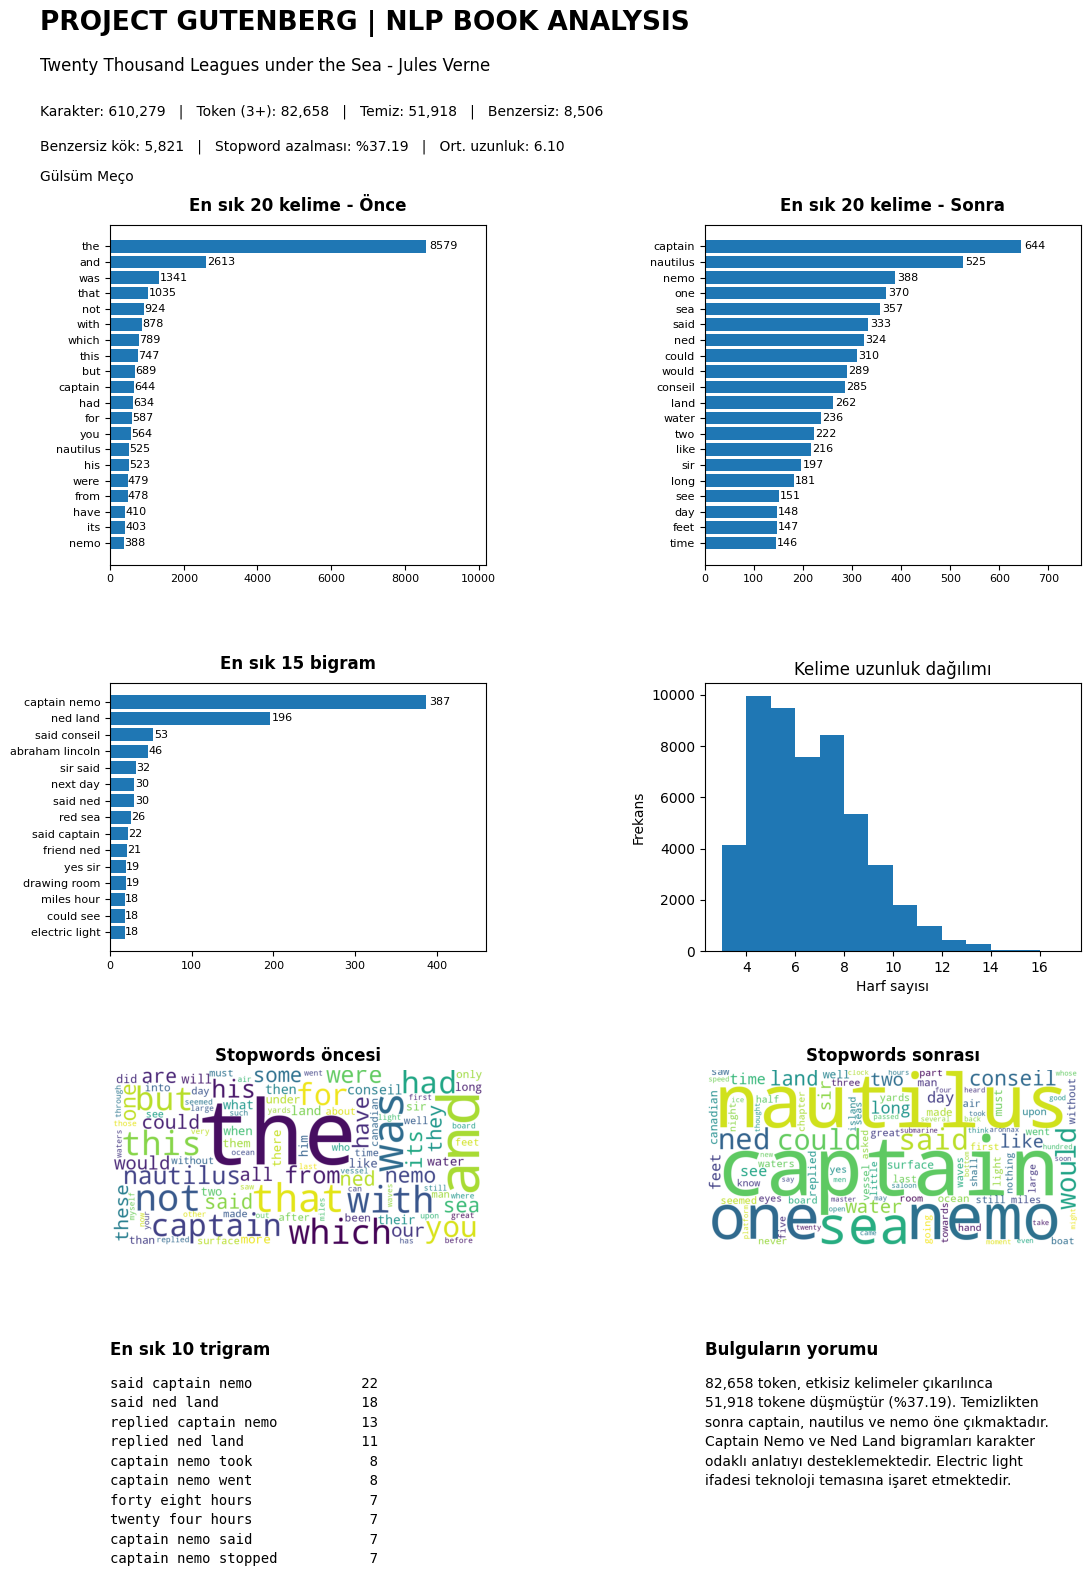

In [9]:

from collections import Counter
from wordcloud import WordCloud
from google.colab import files
import matplotlib.pyplot as plt
import textwrap

fig = plt.figure(figsize=(11.7, 16.5), facecolor="white")
gs = fig.add_gridspec(4, 2, left=.12, right=.95, top=.85,
                      bottom=.06, hspace=.50, wspace=.58,
                      height_ratios=[3.3, 2.6, 1.7, 1.6])

fig.text(.06, .968, "PROJECT GUTENBERG | NLP BOOK ANALYSIS",
         fontsize=19, weight="bold")
fig.text(.06, .943, "Twenty Thousand Leagues under the Sea - Jules Verne", fontsize=12)
fig.text(.06, .916, f"Karakter: {len(text):,}   |   Token (3+): {len(tokens):,}   |   Temiz: {len(clean_tokens):,}   |   Benzersiz: {len(set(clean_tokens)):,}", fontsize=10)
fig.text(.06, .895, f"Benzersiz kök: {len(set(stems)):,}   |   Stopword azalması: %{azalma:.2f}   |   Ort. uzunluk: {sum(uzunluklar)/len(uzunluklar):.2f}", fontsize=10)
fig.text(.06, .876, "Gülsüm Meço", fontsize=10)

def bars(ax, data, title):
    names, counts = zip(*data[::-1])
    names = [" ".join(n) if isinstance(n, tuple) else n for n in names]
    ax.barh(names, counts)
    ax.set_xlim(0, max(counts)*1.19)
    ax.tick_params(labelsize=8)
    for y, count in enumerate(counts):
        ax.text(count*1.01, y, str(count), va="center", fontsize=8)
    ax.set_title(title, fontsize=12, weight="bold", pad=10)

for col, words, label in [(0, tokens, "En sık 20 kelime - Önce"),
                          (1, clean_tokens, "En sık 20 kelime - Sonra")]:
    bars(fig.add_subplot(gs[0, col]), Counter(words).most_common(20), label)

bars(fig.add_subplot(gs[1, 0]), bigrams, "En sık 15 bigram")

ax = fig.add_subplot(gs[1, 1])
ax.hist(uzunluklar, bins=range(3, max(uzunluklar)+2))
ax.set(title="Kelime uzunluk dağılımı", xlabel="Harf sayısı", ylabel="Frekans")

for col, words, title in [(0, tokens, "Stopwords öncesi"),
                          (1, clean_tokens, "Stopwords sonrası")]:
    ax = fig.add_subplot(gs[2, col])
    cloud = WordCloud(width=950, height=450, background_color="white")
    cloud.generate_from_frequencies(dict(Counter(words).most_common(100)))
    ax.imshow(cloud)
    ax.set_title(title, fontsize=12, weight="bold")
    ax.axis("off")

ax = fig.add_subplot(gs[3, 0])
ax.axis("off")
ax.set_title("En sık 10 trigram", fontsize=12, weight="bold", loc="left")
ax.text(0, .92, "\n".join(f"{' '.join(ng):<29}{n:>3}" for ng, n in trigrams),
        va="top", fontfamily="monospace", fontsize=10, linespacing=1.5)

ax = fig.add_subplot(gs[3, 1])
ax.axis("off")
ax.set_title("Bulguların yorumu", fontsize=12, weight="bold", loc="left")

yorum = (
    f"{len(tokens):,} token, etkisiz kelimeler çıkarılınca {len(clean_tokens):,} "
    f"tokene düşmüştür (%{azalma:.2f}). "
    "Temizlikten sonra captain, nautilus ve nemo öne çıkmaktadır. "
    "Captain Nemo ve Ned Land bigramları karakter odaklı anlatıyı desteklemektedir. "
    "Electric light ifadesi teknoloji temasına işaret etmektedir."
)
ax.text(0, .92, textwrap.fill(yorum, 48), va="top", fontsize=10, linespacing=1.5)

plt.savefig("NLP_Odev1_Gulsum_Meco.pdf")
plt.show()
files.download("NLP_Odev1_Gulsum_Meco.pdf")


**8. Sonuçların Raporlanması**

Metin ön işleme, frekans analizi, N-gram analizi ve istatistiksel işlemlerden elde edilen bulgular tek sayfalık bir PDF raporunda birleştirilmiştir. Raporda karşılaştırmalı grafikler, kelime bulutları, temel istatistikler ve bulguların kısa değerlendirmesi sunulmuştur.